# Sample properties · magnitude and redshift

The former Figure 1 panels c,d, now one separate horizontal figure. No figure
or panel titles; labels, legends and binning are preserved. Train/validation/test
catalog metadata only; no held-out model evaluation. No image mosaics or model outputs are needed.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Works from the repository root or from paper_figures/.
here = Path.cwd()
workspace = here if (here / 'figure_utils.py').exists() else here / 'paper_figures'
if str(workspace) not in sys.path:
    sys.path.insert(0, str(workspace))
from figure_utils import (ROOT, FIGURES, DATA, COLORS, style, read_json, export,
                          panel, box, arrow, verified_sources, completed_evaluation,
                          run_inventory, sha)
%matplotlib inline
style()
VERSION = 'v02'

In [2]:
# Review controls: figure size, histogram bins, colors, export version.
FIGSIZE = (7.2, 2.8)
PROPERTY_SPLITS = ['train', 'validation', 'test']
manifest_path = DATA / 'manifest.json'
objects_path = DATA / 'objects.csv'
manifest = read_json(manifest_path)
objects = pd.read_csv(objects_path)
assert len(objects) == manifest['accepted']
assert objects.id_classic.is_unique and objects.row.is_unique
assert objects.groupby('split').size().to_dict() == manifest['split_counts']
assert manifest['accepted'] + sum(manifest['rejection_counts'].values()) == manifest['candidates']
display(pd.DataFrame({'split': list(manifest['split_counts']),
                      'galaxies': list(manifest['split_counts'].values())}))
print('Selection:', manifest['selection'])
print('Quality:', manifest['quality'])

,split,galaxies
0,train,17816
1,test,2876
2,validation,2118


Selection: lp_type==0; ACS_F814W_MAG<25; .01<ez_z_phot<3; 4<FLUX_RADIUS<500; existing dated coverage candidates
Quality: DQ==0; finite SCI and positive finite RMS<1e7; >=95% coverage each instrument; central 5x5 NISP /25x25 HR fully valid


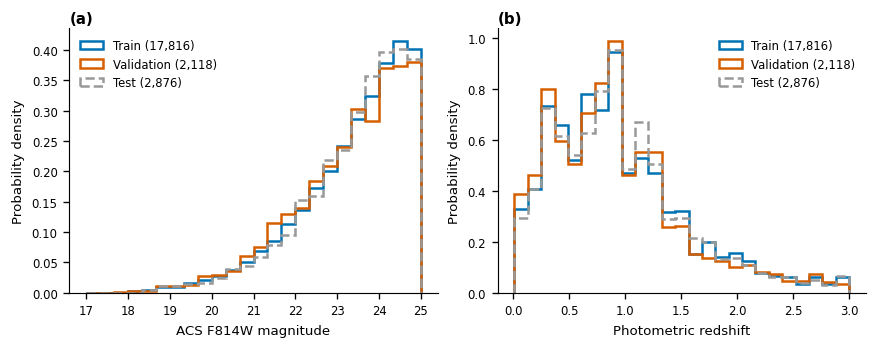

In [3]:
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, layout="constrained")
# Preserve the previous bin edges; adding test does not redefine the bins.
population = objects[objects.split.isin(['train', 'validation'])]
mag_bins = np.linspace(np.floor(population.ACS_F814W_MAG.min()), 25, 25)
z_bins = np.linspace(.01, 3, 26)
for ax, column, bins, xlabel, letter, title in [
    (axes[0], 'ACS_F814W_MAG', mag_bins, 'ACS F814W magnitude', 'a', 'Optical selection'),
    (axes[1], 'ez_z_phot', z_bins, 'Photometric redshift', 'b', 'Redshift distribution')]:
    for split in PROPERTY_SPLITS:
        data = objects.loc[objects.split == split, column].dropna()
        ax.hist(data, bins=bins, density=True, histtype='step', linewidth=1.5,
                color=COLORS[split], linestyle='--' if split == 'test' else '-',
                label=f'{split.capitalize()} ({len(data):,})')
    ax.set(xlabel=xlabel, ylabel='Probability density')
    ax.legend(frameon=False)
    ax.text(0, 1.02, f'({letter})', transform=ax.transAxes, fontsize=9, fontweight='bold')
plt.show()


In [4]:
paths = export(fig, f'fig01b_sample_properties_{VERSION}', '01b_sample_properties.ipynb',
    [manifest_path, objects_path],
    dict(figsize=FIGSIZE, property_splits=PROPERTY_SPLITS,
         magnitude_bins=mag_bins.tolist(), redshift_bins=z_bins.tolist(),
         test_access='catalog magnitude/redshift only; no images, predictions or performance metrics'),
    status='sample properties: separate horizontal figure, train/validation/test catalog metadata only')

Exported: fig01b_sample_properties_v02.pdf, fig01b_sample_properties_v02.svg, fig01b_sample_properties_v02.png


## Working caption

Optical-magnitude (a) and photometric-redshift (b) distributions of the matched
training (17,816), validation (2,118) and reserved-test (2,876) samples. Each
histogram is normalized to unit integral, using the same bins for all splits.
The test distribution is dashed gray. The ACS F814W magnitude cut is 25, and
the selected photometric-redshift range is 0.01–3. The sample is optically
selected, not a NISP-complete galaxy sample. Figure numbering is provisional.

## How the splits are used

- **Training:** optimizer updates and fitting the fixed normalization scales.
- **Validation:** development, checkpoint selection, architecture comparisons,
  and refinement of the observed-shape measurement protocol. Residual runs
  select checkpoints by masked MAE on all 2,118 validation objects; diffusion
  uses generated physical MAE on a fixed 256-object monitor, followed by the
  full 2,118-object validation analysis. Current shape comparisons are therefore
  development results, not final held-out performance estimates.
- **Test:** reserved for final reconstruction and observed-shape evaluation
  after the models, checkpoints, measurement settings, masks and reporting
  choices are frozen. Do not retune those choices based on test results.

Splits use disjoint 3-arcmin sky blocks, with 10-arcsec boundary buffers rather
than an independent random split of neighboring galaxies. This reduces local
spatial leakage, but all splits are in COSMOS and do not establish generalization
to another field. This figure reads test catalog properties only; no test images
or model outputs are accessed. These histograms describe the fixed split and
must not be used to reshuffle it or tune the models to the test distribution.
